In [48]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)

file_path = "data/psam_p12.csv "

selected_columns = [
    "AGEP",   # Age
    "SEX",    # Sex
    "SCHL",   # Educational attainment
    "RAC1P",  # Race
    "HISP",   # Hispanic origin
    "DIS",    # Disability status
    "ESR",    # Employment status recode
    "COW",    # Class of worker
    "WKHP",   # Usual hours worked per week
    "WAGP",   # Wages or salary income
    "PINCP",  # Total personal income
    "OCCP",   # Occupation
    "INDP",   # Industry
    "STATE",  # State code
    "PUMA",   # Public Use Microdata Area
    "PWGTP"   # Person's weight
]

df = pd.read_csv(file_path, usecols=selected_columns)

print("Initial shape:", df.shape)
df.head()

Initial shape: (213167, 16)


,PUMA,STATE,PWGTP,AGEP,COW,SCHL,SEX,WAGP,WKHP,DIS,ESR,HISP,INDP,OCCP,PINCP,RAC1P
0,10504,12,38,47,1.0,17.0,1,4600.0,40.0,1,6.0,1,170.0,6050.0,4600.0,1
1,4798,12,55,35,1.0,17.0,1,0.0,NaN,1,6.0,1,770.0,6200.0,0.0,1
2,9102,12,16,95,NaN,20.0,1,0.0,NaN,1,6.0,1,NaN,NaN,71000.0,1
3,7302,12,62,25,5.0,21.0,1,400.0,50.0,2,6.0,1,9470.0,425.0,1450.0,1
4,8500,12,46,26,NaN,15.0,1,0.0,NaN,2,6.0,1,NaN,NaN,0.0,2


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 213167 entries, 0 to 213166
Data columns (total 16 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   PUMA    213167 non-null  int64  
 1   STATE   213167 non-null  int64  
 2   PWGTP   213167 non-null  int64  
 3   AGEP    213167 non-null  int64  
 4   COW     123585 non-null  float64
 5   SCHL    208675 non-null  float64
 6   SEX     213167 non-null  int64  
 7   WAGP    186848 non-null  float64
 8   WKHP    105173 non-null  float64
 9   DIS     213167 non-null  int64  
 10  ESR     184806 non-null  float64
 11  HISP    213167 non-null  int64  
 12  INDP    123585 non-null  float64
 13  OCCP    123585 non-null  float64
 14  PINCP   186848 non-null  float64
 15  RAC1P   213167 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 26.0 MB


In [3]:
df.isna().sum().sort_values(ascending=False)

WKHP     107994
COW       89582
INDP      89582
OCCP      89582
ESR       28361
WAGP      26319
PINCP     26319
SCHL       4492
PUMA          0
STATE         0
PWGTP         0
AGEP          0
SEX           0
DIS           0
HISP          0
RAC1P         0
dtype: int64

In [4]:
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
PUMA,213167.0,6996.187834,3703.753104,101.0,3107.0,8602.0,9909.0,12704.0
STATE,213167.0,12.000000,0.000000,12.0,12.0,12.0,12.0,12.0
PWGTP,213167.0,109.642745,95.729874,1.0,54.0,80.0,127.0,2037.0
AGEP,213167.0,46.788509,24.103677,0.0,27.0,49.0,67.0,95.0
COW,123585.0,2.269046,2.080433,1.0,1.0,1.0,3.0,9.0
SCHL,208675.0,16.897141,5.335331,1.0,16.0,18.0,21.0,24.0
SEX,213167.0,1.513715,0.499813,1.0,1.0,2.0,2.0,2.0
WAGP,186848.0,34057.913802,66403.342077,0.0,0.0,4000.0,47700.0,570000.0
WKHP,105173.0,37.698830,12.853738,1.0,35.0,40.0,40.0,99.0
DIS,213167.0,1.831240,0.374540,1.0,2.0,2.0,2.0,2.0


In [5]:
work_df = df.copy()

In [6]:
work_df = work_df[(work_df["AGEP"] >= 18) & (work_df["AGEP"] <= 66)].copy()

print("Shape after age filter:", work_df.shape)

Shape after age filter: (126430, 16)


In [7]:
duplicate_count = work_df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

Exact duplicate rows: 92


In [8]:
work_df.dtypes

PUMA       int64
STATE      int64
PWGTP      int64
AGEP       int64
COW      float64
SCHL     float64
SEX        int64
WAGP     float64
WKHP     float64
DIS        int64
ESR      float64
HISP       int64
INDP     float64
OCCP     float64
PINCP    float64
RAC1P      int64
dtype: object

In [9]:
integer_columns = [
    "AGEP", "SEX", "SCHL", "RAC1P", "HISP", "DIS",
    "ESR", "COW", "WKHP", "OCCP", "INDP", "STATE",
    "PUMA", "PWGTP"
]

for col in integer_columns:
    work_df[col] = pd.to_numeric(work_df[col], errors="coerce").astype("Int64")

numeric_columns = ["WAGP", "PINCP"]

for col in numeric_columns:
    work_df[col] = pd.to_numeric(work_df[col], errors="coerce")

In [10]:
quality_report = pd.DataFrame({
    "missing_count": work_df.isna().sum(),
    "missing_pct": (work_df.isna().mean() * 100).round(2),
    "unique_values": work_df.nunique(dropna=True),
    "dtype": work_df.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

quality_report

,missing_count,missing_pct,unique_values,dtype
WKHP,31453,24.88,97,Int64
COW,19912,15.75,9,Int64
INDP,19912,15.75,265,Int64
OCCP,19912,15.75,530,Int64
PUMA,0,0.00,168,Int64
STATE,0,0.00,1,Int64
PWGTP,0,0.00,879,Int64
AGEP,0,0.00,49,Int64
SCHL,0,0.00,24,Int64
SEX,0,0.00,2,Int64


In [11]:
for col in ["SEX", "RAC1P", "HISP", "DIS", "ESR", "SCHL"]:
    print(f"\n--- {col} ---")
    print(work_df[col].value_counts(dropna=False))


--- SEX ---
SEX
2    63903
1    62527
Name: count, dtype: Int64

--- RAC1P ---
RAC1P
1    72815
9    25036
2    14659
8     8409
6     4693
3      553
5      147
7      109
4        9
Name: count, dtype: Int64

--- HISP ---
HISP
1     91098
4     10268
3      6313
2      3980
16     3050
21     2271
5      1575
24     1164
9      1129
19      856
7       844
8       835
17      603
23      527
11      509
13      497
10      262
6       198
15      172
20      114
14      106
18       28
22       20
12       11
Name: count, dtype: Int64

--- DIS ---
DIS
2    110931
1     15499
Name: count, dtype: Int64

--- ESR ---
ESR
1    86201
6    34100
3     3937
2     1506
4      681
5        5
Name: count, dtype: Int64

--- SCHL ---
SCHL
21    28331
16    26898
19    15420
20    13015
22    11380
18     8613
17     5936
23     3094
15     3078
14     2213
1      2206
24     1836
13     1399
12     1090
11      595
9       555
10      218
8       160
6       102
7        98
5        63
2        

In [12]:
work_df.to_csv("psam_p12_working_clean.csv", index=False)

In [71]:
# IMPORTS — All libraries used throughout the notebook

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Machine learning — models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Machine learning — utilities
from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_val_score, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay,
    accuracy_score, f1_score, recall_score
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Database
import mysql.connector
from datetime import datetime

import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")

Libraries loaded successfully.


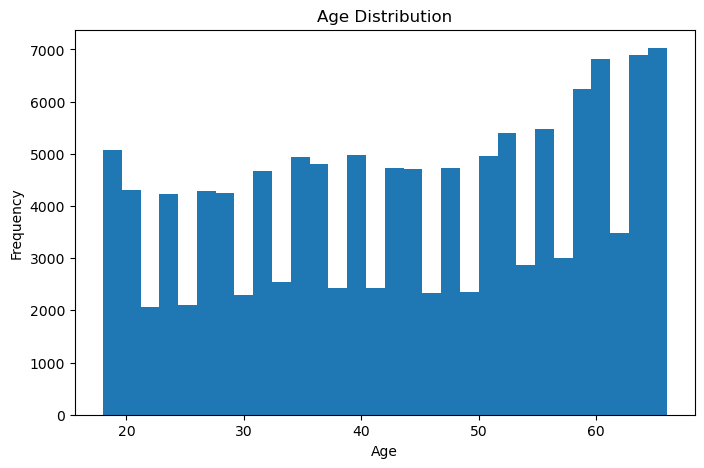

In [49]:
plt.figure(figsize=(8,5))
plt.hist(work_df["AGEP"].dropna(), bins=30)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.savefig("figures_du/age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
This histogram shows the age distribution of the working dataset after applying the 18–66 age filter.  
The sample is spread across the full working-age range, with relatively stronger representation in the older age bands.  
This confirms that age remains an important contextual variable for the later labour disparity analysis.

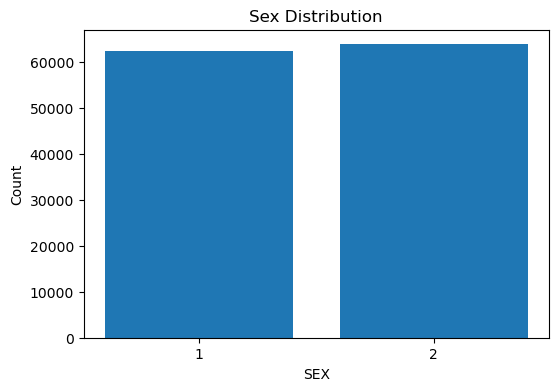

In [50]:
sex_counts = work_df["SEX"].value_counts(dropna=False).sort_index()

plt.figure(figsize=(6,4))
plt.bar(sex_counts.index.astype(str), sex_counts.values)
plt.title("Sex Distribution")
plt.xlabel("SEX")
plt.ylabel("Count")
plt.savefig("figures_du/sex_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
The chart shows that the dataset is relatively balanced by sex, with similar counts for both categories. 
This is useful for the project because it reduces the risk of extreme underrepresentation at the descriptive stage.  
However, balanced group size does not imply equal labour outcomes, so further analysis is still required.

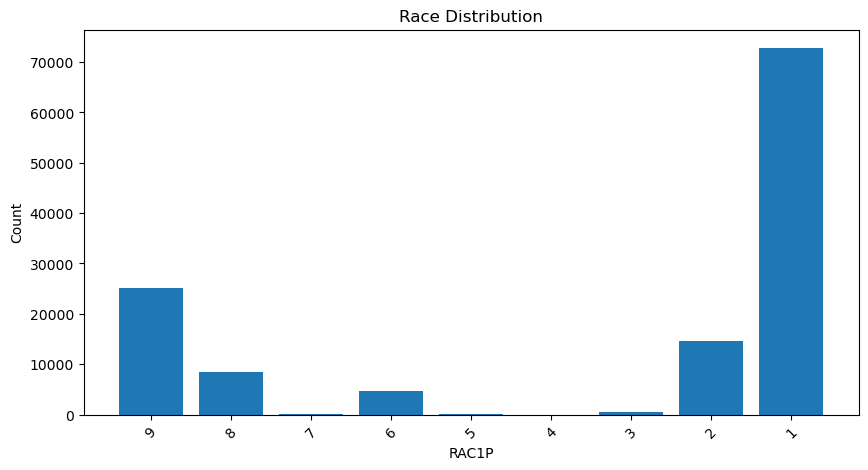

In [51]:
race_counts = work_df["RAC1P"].value_counts(dropna=False).sort_index(ascending=False)

plt.figure(figsize=(10,5))
plt.bar(race_counts.index.astype(str), race_counts.values)
plt.title("Race Distribution")
plt.xlabel("RAC1P")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.savefig("figures_du/race_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
The chart shows that the dataset is not evenly distributed across race categories, with one group clearly dominating the sample and several others appearing in much smaller numbers.  
This is important for the project because unequal representation may affect later disparity analysis and the stability of group-level comparisons.  
It also suggests that some categories may need careful handling or aggregation during the auditing stage.

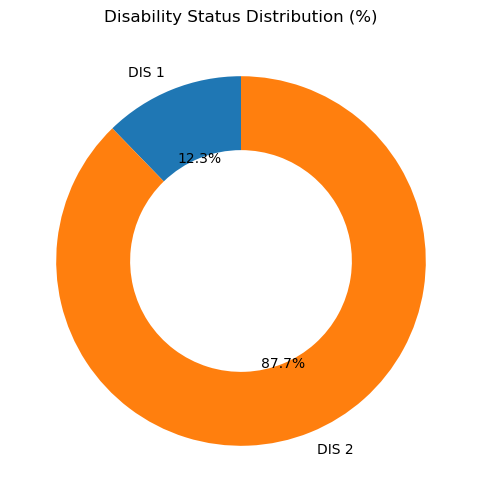

In [52]:
dis_pct = (
    work_df["DIS"]
    .value_counts(normalize=True, dropna=False)
    .sort_index() * 100
)

labels = [f"DIS {idx}" for idx in dis_pct.index]

plt.figure(figsize=(6,6))
plt.pie(
    dis_pct.values,
    labels=labels, 
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Disability Status Distribution (%)")
plt.savefig("figures_du/disability_distribution_donut.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
The chart shows the proportional distribution of disability status in the working dataset.  
Most individuals fall into one category, while the other represents a smaller share of the sample.  
This is important because unequal group size may influence later disparity comparisons.

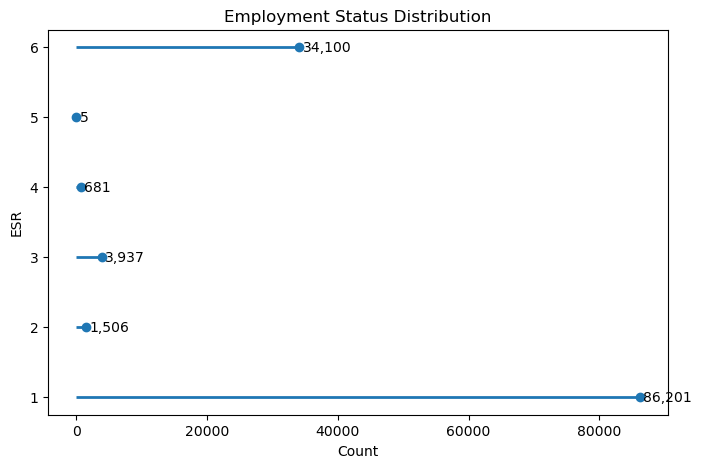

In [53]:
esr_counts = work_df["ESR"].value_counts(dropna=False).sort_index()

plt.figure(figsize=(8,5))
plt.hlines(y=esr_counts.index.astype(str), xmin=0, xmax=esr_counts.values, linewidth=2)
plt.plot(esr_counts.values, esr_counts.index.astype(str), "o")

plt.title("Employment Status Distribution")
plt.xlabel("Count")
plt.ylabel("ESR")

for i, value in zip(esr_counts.index.astype(str), esr_counts.values):
    plt.text(value + 500, i, f"{value:,}", va="center")

plt.savefig("figures_du/employment_status_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
The dot plot shows that the employment status categories are very unevenly distributed in the dataset.  
A small number of ESR categories account for most observations, while others represent only a minor share.  
This is important for the project because the labour outcome will need to be defined carefully from these categories.

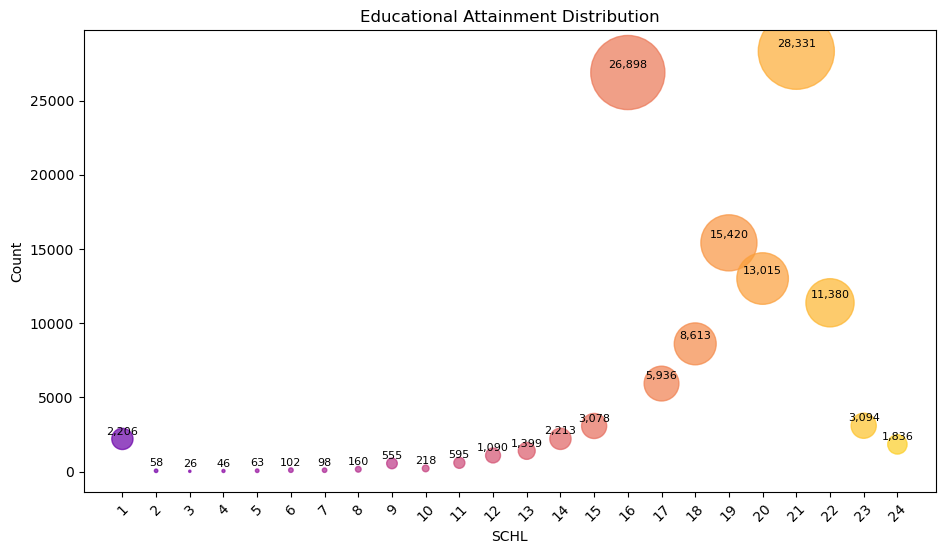

In [54]:
schl_counts = work_df["SCHL"].value_counts(dropna=False).sort_index()

x = np.arange(len(schl_counts))
y = schl_counts.values
sizes = (y / y.max()) * 3000
colors = plt.cm.plasma(np.linspace(0.2, 0.9, len(y)))

plt.figure(figsize=(11, 6))
plt.scatter(x, y, s=sizes, c=colors, alpha=0.7)

plt.xticks(x, schl_counts.index.astype(str), rotation=45)
plt.title("Educational Attainment Distribution")
plt.xlabel("SCHL")
plt.ylabel("Count")

for i, value in enumerate(y):
    plt.text(i, value + 300, f"{value:,}", ha="center", fontsize=8)

plt.savefig("figures_du/education_distribution_bubble.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
The bubble chart shows that educational attainment is unevenly distributed across categories in the working dataset.  
Some education levels clearly have much larger representation than others, both in count and visual weight.  
This reinforces the importance of education as a contextual variable for later labour disparity analysis.

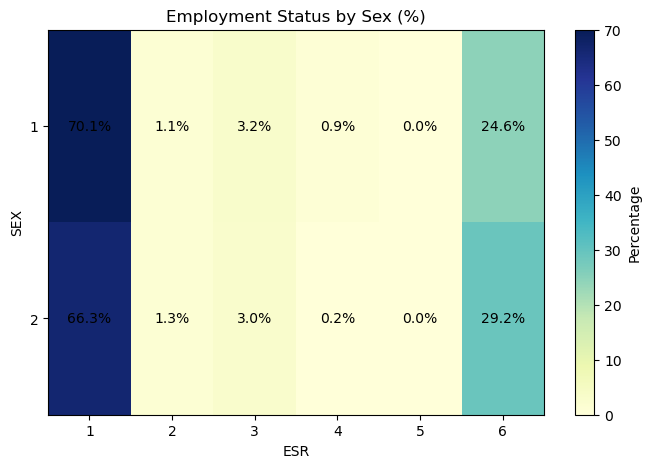

In [55]:
employment_by_sex_pct = pd.crosstab(
    work_df["SEX"],
    work_df["ESR"],
    normalize="index"
) * 100

plt.figure(figsize=(8,5))
plt.imshow(employment_by_sex_pct, aspect="auto", cmap="YlGnBu")

plt.title("Employment Status by Sex (%)")
plt.xlabel("ESR")
plt.ylabel("SEX")

plt.xticks(range(len(employment_by_sex_pct.columns)), employment_by_sex_pct.columns)
plt.yticks(range(len(employment_by_sex_pct.index)), employment_by_sex_pct.index)

for i in range(employment_by_sex_pct.shape[0]):
    for j in range(employment_by_sex_pct.shape[1]):
        plt.text(
            j, i,
            f"{employment_by_sex_pct.iloc[i, j]:.1f}%",
            ha="center", va="center", color="black"
        )

plt.colorbar(label="Percentage")
plt.savefig("figures_du/employment_status_by_sex_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
The heatmap shows the percentage distribution of employment status within each sex category.  
This makes it easier to compare relative labour-status patterns rather than only raw counts.  
It is a more useful view for the project because it begins to highlight group differences in a comparative way.

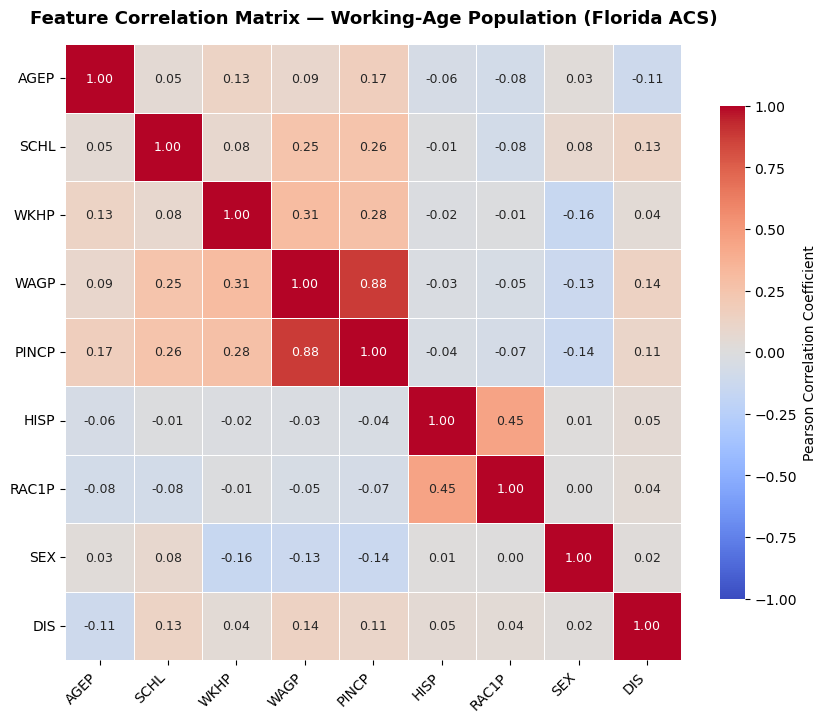

In [58]:
# Select numeric columns for correlation analysis
numeric_cols = ["AGEP", "SCHL", "WKHP", "WAGP", "PINCP", "HISP", "RAC1P",
                "SEX", "DIS"]

# Compute correlation matrix — only on working-age filtered dataset
corr_matrix = work_df[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,                    # Show correlation values in each cell
    fmt=".2f",                     # Two decimal places
    cmap="coolwarm",               # Blue = negative, Red = positive
    center=0,                      # Centre the colormap at zero
    vmin=-1, vmax=1,               # Fix scale to full correlation range
    square=True,                   # Square cells for readability
    linewidths=0.5,                # Thin lines between cells
    linecolor="white",
    annot_kws={"size": 9},
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)

plt.title("Feature Correlation Matrix — Working-Age Population (Florida ACS)",
          fontsize=13, fontweight="bold", pad=15)

# Improve axis label readability
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout
plt.savefig("figures_du/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

##### Interpretation:
The correlation matrix reveals the linear relationships between all numeric variables in the working-age ACS dataset. Key observations:

- WAGP and PINCP show strong positive correlation, as wage income is a component of total personal income. Both are excluded from the feature matrix in the Modelling phase to prevent data leakage.

- WKHP (hours worked) shows moderate positive correlation with WAGP and PINCP, further justifying its exclusion as a feature — it is only observable for employed individuals.

- Demographic variables (AGEP, SEX, RAC1P, DIS, HISP) show weak correlations with each other, indicating limited multicollinearity among the features retained for modelling.

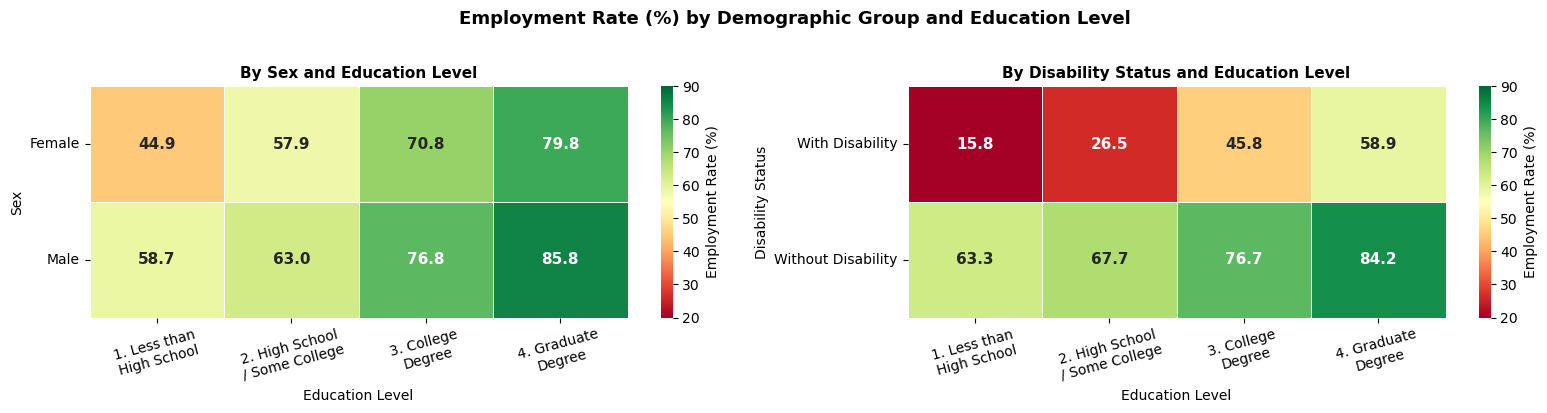

In [59]:
# Data Understanding - Employment Rate Heatmap By Demographic Group

df_heatmap = work_df.copy()

df_heatmap["SEX_LABEL"] = df_heatmap["SEX"].map({1: "Male", 2: "Female"})

df_heatmap["DIS_LABEL"] = df_heatmap["DIS"].map({
    1: "With Disability",
    2: "Without Disability"
})

def education_group(schl):
    if schl <= 11:
        return "1. Less than\nHigh School"
    elif schl <= 17:
        return "2. High School\n/ Some College"
    elif schl <= 21:
        return "3. College\nDegree"
    else:
        return "4. Graduate\nDegree"

df_heatmap["SCHL_GROUP"] = df_heatmap["SCHL"].apply(education_group)

df_heatmap["EMPLOYED"] = df_heatmap["ESR"].apply(
    lambda x: 1 if x in [1, 2, 4, 5] else 0
    if pd.notna(x) else np.nan
)
df_heatmap = df_heatmap.dropna(subset=["EMPLOYED"])

# PLOT 1: Employment Rate by Education Level and Sex
pivot_sex_edu = df_heatmap.pivot_table(
    values="EMPLOYED",
    index="SEX_LABEL",
    columns="SCHL_GROUP",
    aggfunc="mean"
) * 100

# PLOT 2: Employment Rate by Education Level and Disability Status
pivot_dis_edu = df_heatmap.pivot_table(
    values="EMPLOYED",
    index="DIS_LABEL",
    columns="SCHL_GROUP",
    aggfunc="mean"
) * 100

# Plot both heatmaps side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
fig.suptitle("Employment Rate (%) by Demographic Group and Education Level",
             fontsize=13, fontweight="bold", y=1.02)

heatmap_kwargs = dict(
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=20, vmax=90,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 11, "fontweight": "bold"},
    cbar_kws={"label": "Employment Rate (%)"}
)
    
# Plot 1: Sex × Education
sns.heatmap(pivot_sex_edu, ax=axes[0], **heatmap_kwargs)
axes[0].set_title("By Sex and Education Level",
                  fontsize=11, fontweight="bold")
axes[0].set_xlabel("Education Level", fontsize=10)
axes[0].set_ylabel("Sex", fontsize=10)
axes[0].tick_params(axis="x", rotation=15)
axes[0].tick_params(axis="y", rotation=0)

# Plot 2: Disability × Education
sns.heatmap(pivot_dis_edu, ax=axes[1], **heatmap_kwargs)
axes[1].set_title("By Disability Status and Education Level",
                  fontsize=11, fontweight="bold")
axes[1].set_xlabel("Education Level", fontsize=10)
axes[1].set_ylabel("Disability Status", fontsize=10)
axes[1].tick_params(axis="x", rotation=15)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig("figures_du/employment_rate_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation:

These heatmaps reveal structural patterns in employment outcomes across demographic groups BEFORE any modelling is applied:

LEFT CHART (Sex × Education):
- Employment rates increase with education for both sexes, but males consistently show higher employment rates than females at equivalent education levels — a pattern that motivates the sex-based fairness analysis in the Evaluation phase.

RIGHT CHART (Disability × Education):
- Individuals with disabilities show substantially lower employment rates across ALL education levels compared to those without disabilities.
- Even with a Graduate degree, individuals with disabilities have significantly lower employment rates — suggesting that educational attainment alone does not offset the employment disadvantage associated with disability status.
- This finding directly motivates the disability fairness analysis and explains the structural pessimism observed in the model's predictions for this group.

In [60]:
selected_columns = [
    "AGEP", "SEX", "SCHL", "RAC1P", "HISP",
    "DIS", "ESR", "WKHP", "WAGP", "PINCP",
    "COW", "PWGTP"
]

df_raw = pd.read_csv("data/psam_p12.csv", usecols=selected_columns)

# Filter to working-age population (18–66)
df_raw = df_raw[(df_raw["AGEP"] >= 18) & (df_raw["AGEP"] <= 66)].copy()

print(f"Dataset shape after age filter: {df_raw.shape}")
df_raw.head()

Dataset shape after age filter: (126430, 12)


,PWGTP,AGEP,COW,SCHL,SEX,WAGP,WKHP,DIS,ESR,HISP,PINCP,RAC1P
0,38,47,1.0,17.0,1,4600.0,40.0,1,6.0,1,4600.0,1
1,55,35,1.0,17.0,1,0.0,NaN,1,6.0,1,0.0,1
3,62,25,5.0,21.0,1,400.0,50.0,2,6.0,1,1450.0,1
4,46,26,NaN,15.0,1,0.0,NaN,2,6.0,1,0.0,2
5,49,24,1.0,19.0,1,10000.0,12.0,2,3.0,1,10000.0,2


In [61]:
# Record dataset size before removal
rows_before = df_raw.shape[0]

# Remove duplicate rows
df_raw = df_raw.drop_duplicates().copy()

# Record dataset size after removal
rows_after = df_raw.shape[0]

print(f"Rows before duplicate removal: {rows_before:,}")
print(f"Rows after duplicate removal:  {rows_after:,}")
print(f"Duplicates removed:            {rows_before - rows_after}")
print()
print("Dataset is now clean and ready for target variable creation.")

Rows before duplicate removal: 126,430
Rows after duplicate removal:  126,038
Duplicates removed:            392

Dataset is now clean and ready for target variable creation.


The ESR (Employment Status Recode) field contains 6 categories.
For binary classification, these are collapsed into two groups:

   EMPLOYED (1):
     ESR = 1 → Civilian employed, at work
     ESR = 2 → Civilian employed, not at work (e.g., on leave)
     ESR = 4 → Armed forces, at work
     ESR = 5 → Armed forces, not at work

   NOT EMPLOYED (0):
     ESR = 3 → Unemployed
     ESR = 6 → Not in labour force

   EXCLUDED:
     ESR = NaN → Under 16 or institutionalised — dropped from modelling

In [62]:
# Drop rows where ESR is missing (not applicable to modelling)
df_model = df_raw.dropna(subset=["ESR"]).copy()

# Create binary target variable: 1 = Employed, 0 = Not Employed
df_model["EMPLOYED"] = df_model["ESR"].apply(
    lambda x: 1 if x in [1, 2, 4, 5] else 0
)

# Drop ESR now that the target variable has been created
# ESR must not be used as a feature — it would cause data leakage
df_model = df_model.drop(columns=["ESR"])

print("Target variable distribution:")
print(df_model["EMPLOYED"].value_counts())
print()
print(f"Employment rate: {df_model['EMPLOYED'].mean():.2%}")
print()
print("ESR column removed — data leakage prevented.")
print(f"df_model shape: {df_model.shape}")

Target variable distribution:
EMPLOYED
1    88349
0    37689
Name: count, dtype: int64

Employment rate: 70.10%

ESR column removed — data leakage prevented.
df_model shape: (126038, 12)


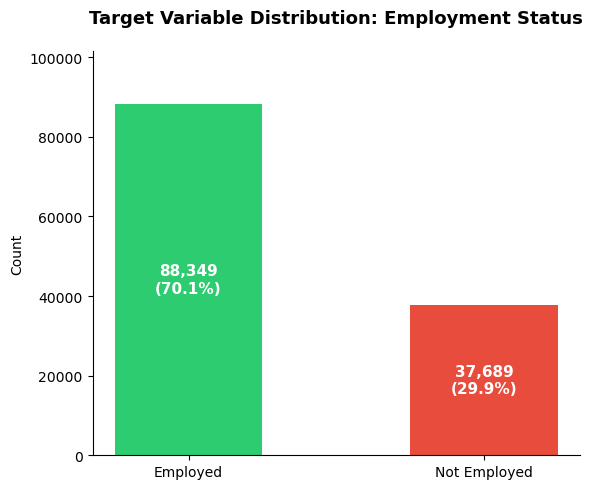

In [63]:
counts = df_model["EMPLOYED"].value_counts()
labels = ["Employed", "Not Employed"]

fig, ax = plt.subplots(figsize=(6, 5))

bars = ax.bar(labels, counts.values, color=["#2ecc71", "#e74c3c"], width=0.5)

# Title with enough top padding to avoid overlap
ax.set_title("Target Variable Distribution: Employment Status",
             fontsize=13, fontweight="bold", pad=20)
ax.set_ylabel("Count")

# Move annotations INSIDE the bars to avoid overlapping with title
for i, v in enumerate(counts.values):
    ax.text(i, v * 0.5,                          # Position at 50% height of bar
            f"{v:,}\n({v/len(df_model):.1%})",
            ha="center", va="center",
            fontweight="bold", fontsize=11,
            color="white")                        # White text inside bars

ax.set_ylim(0, max(counts.values) * 1.15)        # Extra space at top
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figures_du/target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [64]:
all_cols = ["AGEP", "SEX", "SCHL", "RAC1P", "HISP",
            "DIS", "WKHP", "WAGP", "PINCP", "COW"]

X_all = df_model[all_cols].copy()
y_all = df_model["EMPLOYED"]
X_all = X_all.fillna(X_all.median())

X_tr_all, X_te_all, y_tr_all, y_te_all = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)

lr_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=500, random_state=42))
])
lr_initial.fit(X_tr_all, y_tr_all)

auc_initial = roc_auc_score(y_te_all, lr_initial.predict_proba(X_te_all)[:, 1])
acc_initial = lr_initial.score(X_te_all, y_te_all)

print(f"ROC-AUC:  {auc_initial:.4f}")
print(f"Accuracy: {acc_initial:.4f}")

ROC-AUC:  0.9524
Accuracy: 0.9075


AUC is suspiciously high for a demographic-only dataset. Let's check if some variables only have values for employed individuals.

In [66]:
# Check median values by employment status
suspect_cols = ["WAGP", "WKHP", "PINCP", "COW"]
employed     = df_model[df_model["EMPLOYED"] == 1]
not_employed = df_model[df_model["EMPLOYED"] == 0]

print(f"{'Variable':<10} {'Employed (median)':<25} {'Not Employed (median)':}")
print("-" * 55)
for col in suspect_cols:
    if col in df_model.columns:
        med_emp  = employed[col].median()
        med_nemp = not_employed[col].median()
        print(f"{col:<10} {str(med_emp):<25} {str(med_nemp)}")

Variable   Employed (median)         Not Employed (median)
-------------------------------------------------------
WAGP       45000.0                   0.0
WKHP       40.0                      35.0
PINCP      50000.0                   2000.0
COW        1.0                       1.0


In [67]:
# Drop all columns that cause data leakage (direct or indirect)
cols_to_drop = ["PWGTP", "WAGP", "WKHP", "PINCP", "COW"]
df_features = df_model.drop(columns=cols_to_drop)

# Define feature matrix (X) and target vector (y)
X = df_features.drop(columns=["EMPLOYED"])   # All columns except the target
y = df_features["EMPLOYED"]                  # The binary target variable

print("Feature columns used for modelling:")
for col in X.columns:
    print(f"  - {col}")

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape:  {y.shape}")

Feature columns used for modelling:
  - AGEP
  - SCHL
  - SEX
  - DIS
  - HISP
  - RAC1P

Feature matrix shape: (126038, 6)
Target vector shape:  (126038,)


In [68]:
# Convert nominal categorical columns to string so pd.get_dummies handles them
nominal_cols = ["SEX", "RAC1P", "HISP", "DIS"]

# Fill NaN in categorical columns before encoding (mode imputation)
for col in nominal_cols:
    X[col] = X[col].fillna(X[col].mode()[0])          # Fill missing with most frequent value
    X[col] = X[col].astype(str)                        # Convert to string for get_dummies

# Apply One-Hot Encoding — drop_first=True avoids multicollinearity
X_encoded = pd.get_dummies(X, columns=nominal_cols, drop_first=True)

# Fill remaining missing values in numeric columns (AGEP, SCHL, WKHP, PINCP)
# Using median imputation — robust to outliers in income/hours columns
X_encoded = X_encoded.fillna(X_encoded.median())

print(f"Shape after encoding: {X_encoded.shape}")
print(f"\nTotal features after One-Hot Encoding: {X_encoded.shape[1]}")
print("\nFeature list:")
print(X_encoded.columns.tolist())

Shape after encoding: (126038, 35)

Total features after One-Hot Encoding: 35

Feature list:
['AGEP', 'SCHL', 'SEX_2', 'RAC1P_2', 'RAC1P_3', 'RAC1P_4', 'RAC1P_5', 'RAC1P_6', 'RAC1P_7', 'RAC1P_8', 'RAC1P_9', 'HISP_10', 'HISP_11', 'HISP_12', 'HISP_13', 'HISP_14', 'HISP_15', 'HISP_16', 'HISP_17', 'HISP_18', 'HISP_19', 'HISP_2', 'HISP_20', 'HISP_21', 'HISP_22', 'HISP_23', 'HISP_24', 'HISP_3', 'HISP_4', 'HISP_5', 'HISP_6', 'HISP_7', 'HISP_8', 'HISP_9', 'DIS_2']


In [69]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # Preserve class balance in both splits
)

print("Train/Test Split Summary:")
print(f"  Training samples:  {X_train.shape[0]:,} ({X_train.shape[0]/len(y):.0%})")
print(f"  Test samples:      {X_test.shape[0]:,}  ({X_test.shape[0]/len(y):.0%})")
print()
print("Class distribution in training set:")
print(y_train.value_counts(normalize=True).rename({1: "Employed", 0: "Not Employed"}))
print()
print("Class distribution in test set:")
print(y_test.value_counts(normalize=True).rename({1: "Employed", 0: "Not Employed"}))

Train/Test Split Summary:
  Training samples:  100,830 (80%)
  Test samples:      25,208  (20%)

Class distribution in training set:
EMPLOYED
Employed        0.700972
Not Employed    0.299028
Name: proportion, dtype: float64

Class distribution in test set:
EMPLOYED
Employed        0.700968
Not Employed    0.299032
Name: proportion, dtype: float64


In [70]:
# Model Slection - Baseline Algorithm Comparison

models = [
    ("LR",  Pipeline([("scaler", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=1000,
                               class_weight="balanced",
                               random_state=42))])),
    ("LDA", Pipeline([("scaler", StandardScaler()),
                      ("clf", LinearDiscriminantAnalysis())])),
    ("KNN", Pipeline([("scaler", StandardScaler()),
                     ("clf", KNeighborsClassifier())])),
    ("CART",DecisionTreeClassifier(class_weight="balanced",
                                   random_state=42)),
   ("NB",  GaussianNB()),
    ("RF",  RandomForestClassifier(n_estimators=100,
                                  class_weight="balanced",
                                   random_state=42,
                                  n_jobs=-1)),
]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
names   = []

print(f"{'Model':<6}  {'Mean AUC':>10}  {'Std Dev':>10}")
print("-" * 32)

for name, model in models:
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="roc_auc",
       n_jobs=-1
    )
    results.append(cv_scores)
    names.append(name)
    print(f"{name:<6}  {cv_scores.mean():>10.4f}  {cv_scores.std():>10.4f}")

Model     Mean AUC     Std Dev
--------------------------------
LR          0.6889      0.0024
LDA         0.6892      0.0025
KNN            nan         nan
CART        0.6867      0.0053
NB          0.6638      0.0034
RF          0.7156      0.0038


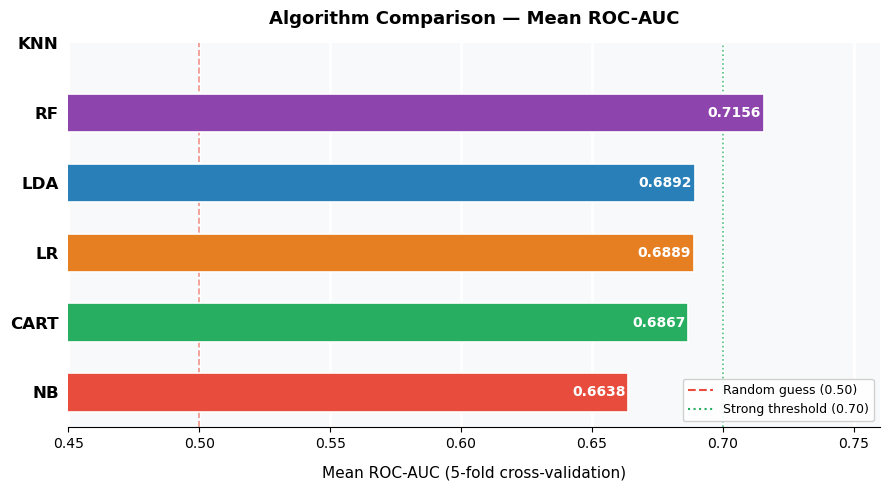

In [72]:
# Visualise model comparison
palette = {
    "RF":   "#8e44ad",
    "LDA":  "#2980b9",
    "CART": "#27ae60",
    "LR":   "#e67e22",
    "NB":   "#e74c3c",
    "KNN":  "#95a5a6",
}
means_arr  = np.array([r.mean() for r in results])
sorted_idx = np.argsort(means_arr)
names_s    = [names[i]  for i in sorted_idx]
means_s    = [means_arr[i] for i in sorted_idx]
colors_s   = [palette.get(names[i], "#95a5a6") for i in sorted_idx]

y_pos = np.arange(len(names_s))

fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor("#ffffff")
ax.set_facecolor("#f8f9fa")

bars = ax.barh(y_pos, means_s,
               color=colors_s,
               height=0.55,
               edgecolor="white",
               linewidth=1.2)

for bar in bars:
    bar.set_zorder(3)

# Value labels inside each bar
for bar, mean, color in zip(bars, means_s, colors_s):
    if not np.isnan(mean):
        ax.text(bar.get_width() - 0.001, bar.get_y() + bar.get_height() / 2,
                f"{mean:.4f}",
                va="center", ha="right",
                fontsize=10, fontweight="bold",
                color="white")

ax.axvline(x=0.50, color="#e74c3c", linestyle="--",
           linewidth=1.2, alpha=0.6, zorder=2,
           label="Random guess (0.50)")

ax.axvline(x=0.70, color="#27ae60", linestyle=":",
           linewidth=1.2, alpha=0.8, zorder=2,
           label="Strong threshold (0.70)")

ax.set_yticks(y_pos)
ax.set_yticklabels(names_s, fontsize=12, fontweight="bold")

ax.set_xlim(0.45, 0.76)
ax.set_xlabel("Mean ROC-AUC (5-fold cross-validation)",
              fontsize=11, labelpad=10)

ax.set_title("Algorithm Comparison — Mean ROC-AUC",
             fontsize=13, fontweight="bold", pad=14)

ax.set_axisbelow(True)
ax.xaxis.grid(True, color="white", linewidth=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(left=False)

ref_lines = [
    plt.Line2D([0],[0], color="#e74c3c", linestyle="--",
               label="Random guess (0.50)"),
    plt.Line2D([0],[0], color="#27ae60", linestyle=":",
               label="Strong threshold (0.70)"),
]
ax.legend(handles=ref_lines, loc="lower right",
          fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig("figures_du/model_selection_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Build pipeline: scale features → fit logistic regression
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),              # Normalise features to mean=0, std=1
    ("classifier", LogisticRegression(
        max_iter=1000,                         # Enough iterations to converge
        class_weight="balanced",               # Compensate for class imbalance
        random_state=42
    ))
])

# Train the model on the training set ONLY
lr_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")
print(f"Features used: {X_train.shape[1]}")
print(f"Training samples: {X_train.shape[0]:,}")

In [ ]:
# Generate predictions on the test set
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]  # Probability of class 1 (Employed)

# Print detailed classification report
print("=" * 55)
print("LOGISTIC REGRESSION — Classification Report")
print("=" * 55)
print(classification_report(y_test, y_pred_lr, target_names=["Not Employed", "Employed"]))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_lr):.4f}")

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    display_labels=["Not Employed", "Employed"],
    colorbar=False,
    cmap="Blues",
    ax=ax
)

ax.set_title("Logistic Regression — Confusion Matrix", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figures_du/lr_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, color="#2980b9", lw=2,
         label=f"Logistic Regression (AUC = {auc_lr:.4f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1, label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Logistic Regression")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures_du/lr_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_lr = cross_val_score(
    lr_pipeline, X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1          # Use all available CPU cores for speed
)

print("Logistic Regression — 5-Fold Cross-Validation Results:")
print(f"  AUC per fold: {[round(s, 4) for s in cv_scores_lr]}")
print(f"  Mean AUC:     {cv_scores_lr.mean():.4f}")
print(f"  Std Dev:      {cv_scores_lr.std():.4f}")
print()
print("Interpretation:")
print(f"  The model achieves a consistent AUC of {cv_scores_lr.mean():.4f} "
      f"(±{cv_scores_lr.std():.4f}) across all 5 folds,")
print("  indicating stable performance with no signs of overfitting.")

In [ ]:
# MODEL 2: RANDOM FOREST CLASSIFIER

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train on the training set ONLY
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")
print(f"Number of trees:    {rf_model.n_estimators}")
print(f"Features used:      {X_train.shape[1]}")
print(f"Training samples:   {X_train.shape[0]:,}")

In [ ]:
# Generate predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]   # Probability of class 1 (Employed)

# Print classification report
print("=" * 55)
print("RANDOM FOREST — Classification Report")
print("=" * 55)
print(classification_report(y_test, y_pred_rf, target_names=["Not Employed", "Employed"]))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf,
    display_labels=["Not Employed", "Employed"],
    colorbar=False,
    cmap="Greens",                        # Green palette to distinguish from LR (Blues)
    ax=ax
)

ax.set_title("Random Forest — Confusion Matrix", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figures_du/rf_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

# Plot both models on the same axes
plt.plot(fpr_lr, tpr_lr, color="#2980b9", lw=2,
         label=f"Logistic Regression (AUC = {auc_lr:.4f})")
plt.plot(fpr_rf, tpr_rf, color="#27ae60", lw=2,
         label=f"Random Forest       (AUC = {auc_rf:.4f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1,
         label="Random Guess (AUC = 0.50)")

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)
plt.title("ROC Curve Comparison: Logistic Regression vs Random Forest",
          fontsize=13, fontweight="bold")
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.savefig("figures_du/roc_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
cv_scores_rf = cross_val_score(
    rf_model, X_train, y_train,
    cv=cv,                        # Same StratifiedKFold object used for LR
    scoring="roc_auc",
    n_jobs=-1
)

print("Random Forest — 5-Fold Cross-Validation Results:")
print(f"  AUC per fold: {[round(s, 4) for s in cv_scores_rf]}")
print(f"  Mean AUC:     {cv_scores_rf.mean():.4f}")
print(f"  Std Dev:      {cv_scores_rf.std():.4f}")
print()
print("Logistic Regression — 5-Fold Cross-Validation (for reference):")
print(f"  Mean AUC:     {cv_scores_lr.mean():.4f}")
print(f"  Std Dev:      {cv_scores_lr.std():.4f}")

In [ ]:
# Extract and sort feature importances
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_encoded.columns
).sort_values(ascending=True).tail(15)    # Top 15 most important features

# Plot horizontal bar chart
plt.figure(figsize=(8, 6))
feature_importance.plot(kind="barh", color="#27ae60")
plt.title("Random Forest — Top 15 Feature Importances",
          fontsize=13, fontweight="bold")
plt.xlabel("Importance (Gini)")
plt.tight_layout()
plt.savefig("figures_du/rf_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nTop 5 most important features:")
top5 = feature_importance.sort_values(ascending=False).head(5)
for feat, imp in top5.items():
    print(f"  {feat}: {imp:.4f}")

In [ ]:

from sklearn.model_selection import GridSearchCV


# Define the parameter grid to search
param_grid = {
    "n_estimators": [100, 200],           # Number of trees
    "max_depth": [10, 20, None],          # Tree depth (None = unlimited)
    "min_samples_split": [2, 5]           # Minimum samples to split a node
}

# Base Random Forest with fixed parameters
rf_base = RandomForestClassifier(
    class_weight="balanced",              # Keep class balancing
    random_state=42,
    n_jobs=-1
)

# GridSearchCV with 3-fold CV (reduced from 5 for speed on large dataset)
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1                             # Print progress during search
)

print("Starting GridSearchCV — this may take a few minutes...")
print(f"Total combinations to evaluate: {2 * 3 * 2 * 3} (12 combinations × 3 folds = 36 fits)")
print()

# Fit on training set ONLY
grid_search.fit(X_train, y_train)

print()
print("Best parameters found:")
print(grid_search.best_params_)
print(f"\nBest CV AUC (training): {grid_search.best_score_:.4f}")

In [ ]:
# Extract the best model from grid search
rf_tuned = grid_search.best_estimator_

# Generate predictions with tuned model
y_pred_tuned = rf_tuned.predict(X_test)
y_prob_tuned = rf_tuned.predict_proba(X_test)[:, 1]

# Print classification report
print("=" * 60)
print("TUNED RANDOM FOREST — Classification Report")
print("=" * 60)
print(classification_report(y_test, y_pred_tuned,
      target_names=["Not Employed", "Employed"]))

auc_tuned = roc_auc_score(y_test, y_prob_tuned)
print(f"ROC-AUC Score (Tuned RF):    {auc_tuned:.4f}")
print(f"ROC-AUC Score (Baseline RF): {auc_rf:.4f}")
print(f"ROC-AUC Score (LR):          {auc_lr:.4f}")
print()

# Determine improvement
improvement = auc_tuned - auc_rf
print(f"Improvement over baseline RF: {improvement:+.4f}")

In [ ]:
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_prob_tuned)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, color="#2980b9", lw=2,
         label=f"Logistic Regression      (AUC = {auc_lr:.4f})")
plt.plot(fpr_rf, tpr_rf, color="#27ae60", lw=2,
         label=f"Random Forest (baseline) (AUC = {auc_rf:.4f})")
plt.plot(fpr_tuned, tpr_tuned, color="#e67e22", lw=2, linestyle="--",
         label=f"Random Forest (tuned)    (AUC = {auc_tuned:.4f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle=":", lw=1,
         label="Random Guess (AUC = 0.50)")

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)
plt.title("Final ROC Curve Comparison — All Models",
          fontsize=13, fontweight="bold")
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.savefig("figures_du/roc_curve_all_models.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Fairness Analysis - Core evaluation function
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score
import warnings
warnings.filterwarnings("ignore")

def evaluate_fairness(X_test_df, y_test, y_pred, y_prob, group_col, group_labels):
    """
    Evaluate model fairness across demographic subgroups.

    Parameters:
    -----------
    X_test_df   : DataFrame with original (pre-encoded) test features
    y_test      : True labels (Series)
    y_pred      : Predicted labels (array)
    y_prob      : Predicted probabilities for class 1 (array)
    group_col   : Column name to group by (e.g., 'SEX')
    group_labels: Dict mapping original values to readable labels

    Returns:
    --------
    DataFrame with metrics per subgroup + fairness gap row
    """

    results = []
    
    for group_val, group_name in group_labels.items():

        # Create mask for this subgroup
        mask = X_test_df[group_col] == group_val

        # Skip if subgroup is too small to evaluate reliably
        if mask.sum() < 30:
            print(f"  Skipping {group_name} — too few samples ({mask.sum()})")
            continue

        y_true_g  = y_test[mask]
        y_pred_g  = y_pred[mask]
        y_prob_g  = y_prob[mask]

        # Calculate metrics for this subgroup
        acc      = accuracy_score(y_true_g, y_pred_g)
        f1_emp   = f1_score(y_true_g, y_pred_g, pos_label=1, zero_division=0)
        f1_nemp  = f1_score(y_true_g, y_pred_g, pos_label=0, zero_division=0)
        rec_emp  = recall_score(y_true_g, y_pred_g, pos_label=1, zero_division=0)
        rec_nemp = recall_score(y_true_g, y_pred_g, pos_label=0, zero_division=0)
        n        = mask.sum()
        emp_rate = y_true_g.mean()   # Actual employment rate in this subgroup

        # ROC-AUC requires both classes to be present
        try:
            auc = roc_auc_score(y_true_g, y_prob_g)
        except ValueError:
            auc = float("nan")

        results.append({
            "Group":            group_name,
            "N (test)":         int(n),
            "Emp. Rate (real)": f"{emp_rate:.1%}",
            "Accuracy":         round(acc, 4),
            "ROC-AUC":          round(auc, 4),
            "F1 (Employed)":    round(f1_emp, 4),
            "F1 (Not Emp.)":    round(f1_nemp, 4),
            "Recall (Emp.)":    round(rec_emp, 4),
            "Recall (Not Emp.)":round(rec_nemp, 4),
        })

    df_results = pd.DataFrame(results)
    
    numeric_cols = ["Accuracy", "ROC-AUC", "F1 (Employed)",
                    "F1 (Not Emp.)", "Recall (Emp.)", "Recall (Not Emp.)"]

    gap_row = {"Group": "⚠️ Fairness Gap", "N (test)": "-", "Emp. Rate (real)": "-"}
    for col in numeric_cols:
        gap_row[col] = round(df_results[col].max() - df_results[col].min(), 4)

    df_results = pd.concat([df_results, pd.DataFrame([gap_row])], ignore_index=True)

    return df_results

In [ ]:
# Rebuild original features before encoding, aligned to test indices
df_original = df_model.drop(columns=["EMPLOYED"]).copy()

# Drop columns not used as features
df_original = df_original.drop(
    columns=[c for c in ["PWGTP", "WAGP", "WKHP", "PINCP", "COW"]
             if c in df_original.columns]
)

# Get the test set rows from the original (pre-encoded) dataframe
X_test_original = df_original.loc[X_test.index]

print("Fairness analysis setup complete.")
print(f"Test set size: {len(X_test_original):,} rows")
print(f"Demographic columns available: {X_test_original.columns.tolist()}")

In [ ]:
sex_labels = {1: "Male", 2: "Female"}

print("=" * 60)
print("FAIRNESS ANALYSIS — SEX")
print("=" * 60)

fairness_sex = evaluate_fairness(
    X_test_original, y_test,
    y_pred_tuned, y_prob_tuned,
    group_col="SEX",
    group_labels=sex_labels
)

print(fairness_sex.to_string(index=False))
print()

# Flag significant gaps
gap_auc = fairness_sex.loc[fairness_sex["Group"] == "⚠️ Fairness Gap", "ROC-AUC"].values[0]
gap_rec = fairness_sex.loc[fairness_sex["Group"] == "⚠️ Fairness Gap", "Recall (Not Emp.)"].values[0]

print("Interpretation:")
if float(gap_auc) > 0.05:
    print(f"  ⚠️  AUC gap of {gap_auc} across sex groups — SIGNIFICANT disparity detected.")
else:
    print(f"  ✅  AUC gap of {gap_auc} across sex groups — within acceptable fairness threshold.")

if float(gap_rec) > 0.05:
    print(f"  ⚠️  Recall (Not Employed) gap of {gap_rec} — model systematically misidentifies")
    print(f"      unemployment for one sex group more than the other.")

In [ ]:
dis_labels = {1: "With Disability", 2: "Without Disability"}

print("=" * 60)
print("FAIRNESS ANALYSIS — DISABILITY STATUS")
print("=" * 60)

fairness_dis = evaluate_fairness(
    X_test_original, y_test,
    y_pred_tuned, y_prob_tuned,
    group_col="DIS",
    group_labels=dis_labels
)

print(fairness_dis.to_string(index=False))
print()

gap_auc = fairness_dis.loc[fairness_dis["Group"] == "⚠️ Fairness Gap", "ROC-AUC"].values[0]
gap_rec = fairness_dis.loc[fairness_dis["Group"] == "⚠️ Fairness Gap", "Recall (Not Emp.)"].values[0]

print("Interpretation:")
if float(gap_auc) > 0.05:
    print(f"  ⚠️  AUC gap of {gap_auc} — SIGNIFICANT performance gap by disability status.")
    print(f"      The model may be less reliable for individuals with disabilities,")
    print(f"      the group most vulnerable to labour market exclusion.")
else:
    print(f"  ✅  AUC gap of {gap_auc} — model performs consistently across disability groups.")

if float(gap_rec) > 0.05:
    print(f"  ⚠️  Recall (Not Employed) gap of {gap_rec} — unemployment detection differs")
    print(f"      significantly between disability groups.")

In [ ]:
# Recode RAC1P into 3 broader groups for statistical reliability
X_test_original["RACE_GROUP"] = X_test_original["RAC1P"].apply(
    lambda x: 1 if x == 1 else (2 if x == 2 else 3)
)

race_labels = {
    1: "White alone",
    2: "Black/African American",
    3: "Other races"
}

print("=" * 60)
print("FAIRNESS ANALYSIS — RACE")
print("=" * 60)

fairness_race = evaluate_fairness(
    X_test_original, y_test,
    y_pred_tuned, y_prob_tuned,
    group_col="RACE_GROUP",
    group_labels=race_labels
)

print(fairness_race.to_string(index=False))
print()

gap_auc = fairness_race.loc[fairness_race["Group"] == "⚠️ Fairness Gap", "ROC-AUC"].values[0]
gap_rec = fairness_race.loc[fairness_race["Group"] == "⚠️ Fairness Gap", "Recall (Not Emp.)"].values[0]

print("Interpretation:")
if float(gap_auc) > 0.05:
    print(f"  ⚠️  AUC gap of {gap_auc} across racial groups — SIGNIFICANT disparity.")
    print(f"      The model discriminates employment status more accurately for some")
    print(f"      racial groups than others — a critical finding for bias auditing.")
else:
    print(f"  ✅  AUC gap of {gap_auc} — model performs consistently across racial groups.")

if float(gap_rec) > 0.05:
    print(f"  ⚠️  Recall (Not Employed) gap of {gap_rec} — the model misses unemployment")
    print(f"      at significantly different rates across racial groups.")

In [ ]:
# Fairness visualisation - Comprenhensive Comparison

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Fairness Analysis — Model Performance by Demographic Group",
             fontsize=14, fontweight="bold", y=1.02)

# ---- Global reference values ----
global_auc      = roc_auc_score(y_test, y_prob_tuned)
global_rec_nemp = recall_score(y_test, y_pred_tuned, pos_label=0)
global_acc      = accuracy_score(y_test, y_pred_tuned)

# ---- All groups and their colors in flat structure ----
all_group_data = [
    # (dataframe,        group_name_override,      color,      metric_key)
    (fairness_sex,  None, "#2980b9", "#e74c3c"),
    (fairness_dis,  None, "#e67e22", "#27ae60"),
    (fairness_race, None, "#8e44ad", "#16a085", "#d35400"),
]
def plot_metric_flat(ax, metric, global_val, title, ylabel):
    """
    Plot a single fairness metric for all demographic groups as flat bars.
    Each demographic dimension is separated by a small gap.
    """
    bar_labels  = []
    bar_values  = []
    bar_colors  = []

    palette_sex  = ["#2980b9", "#e74c3c"]
    palette_dis  = ["#e67e22", "#27ae60"]
    palette_race = ["#8e44ad", "#16a085", "#d35400"]

    datasets = [
        (fairness_sex,  palette_sex),
        (fairness_dis,  palette_dis),
        (fairness_race, palette_race),
    ]

    x_positions = []
    x = 0
    separators = []   # track where dimension gaps are

    for df, palette in datasets:
        df_clean = df[df["Group"] != "⚠️ Fairness Gap"].reset_index(drop=True)
        for i, row in df_clean.iterrows():
            bar_labels.append(row["Group"])
            bar_values.append(float(row[metric]))
            bar_colors.append(palette[i % len(palette)])
            x_positions.append(x)
            x += 1
        separators.append(x - 0.5)
        x += 0.6   # gap between dimensions

    bars = ax.bar(x_positions, bar_values, color=bar_colors,
                  width=0.7, edgecolor="white", linewidth=0.8)

    # Global reference line
    ax.axhline(y=global_val, color="black", linestyle="--",
               linewidth=1.5, label=f"Global: {global_val:.3f}", zorder=5)

    # Dimension separator lines
    for sep in separators[:-1]:
        ax.axvline(x=sep, color="grey", linestyle=":", linewidth=1, alpha=0.5)

 # Annotate bars
    for bar, val in zip(bars, bar_values):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.008,
                f"{val:.3f}", ha="center", va="bottom",
                fontsize=8, fontweight="bold")
        # Red border for below-global bars
        if val < global_val - 0.01:
            bar.set_edgecolor("#e74c3c")
            bar.set_linewidth(2.5)

    ax.set_xticks(x_positions)
    ax.set_xticklabels(bar_labels, fontsize=8, rotation=20, ha="right")
    ax.set_title(title, fontsize=10, fontweight="bold", pad=10)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.legend(fontsize=8, loc="lower right")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

 # Dimension labels below chart
    dim_names  = ["SEX", "DISABILITY", "RACE"]
    dim_centers = []
    x = 0
    for df, _ in datasets:
        df_clean = df[df["Group"] != "⚠️ Fairness Gap"]
        n = len(df_clean)
        dim_centers.append(x + (n - 1) / 2)
        x += n + 0.6 / 1 + 0.6

    for cx, name in zip(dim_centers, dim_names):
        ax.text(cx, -0.18, name, ha="center", va="top",
                fontsize=8.5, fontweight="bold",
                color="grey", transform=ax.get_xaxis_transform())

# ---- Plot 1: ROC-AUC ----
plot_metric_flat(axes[0], "ROC-AUC", global_auc,
                 "ROC-AUC by Demographic Group", "ROC-AUC Score")

# ---- Plot 2: Recall (Not Employed) — most critical ----
plot_metric_flat(axes[1], "Recall (Not Emp.)", global_rec_nemp,
                 "Recall (Not Employed) by Group\n★ Most critical for disparity auditing",
                 "Recall Score")

# ---- Plot 3: Accuracy ----
plot_metric_flat(axes[2], "Accuracy", global_acc,
                 "Accuracy by Demographic Group", "Accuracy Score")

plt.tight_layout()
plt.savefig("figures_du/fairness_analysis_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Fairness Summary 

print("=" * 70)
print("FAIRNESS ANALYSIS — CONSOLIDATED SUMMARY")
print("=" * 70)
print()

dimensions = [
    ("SEX",        fairness_sex,  "Male vs Female"),
    ("DISABILITY", fairness_dis,  "With vs Without Disability"),
    ("RACE",       fairness_race, "White / Black / Other"),
]

summary_rows = []

for dim_name, df_fair, comparison in dimensions:
    gap_row  = df_fair[df_fair["Group"] == "⚠️ Fairness Gap"].iloc[0]
    gap_auc  = float(gap_row["ROC-AUC"])
    gap_rec  = float(gap_row["Recall (Not Emp.)"])
    gap_acc  = float(gap_row["Accuracy"])

    # Worst performing group on Recall (Not Emp.)
    df_clean = df_fair[df_fair["Group"] != "⚠️ Fairness Gap"]
    worst_group = df_clean.loc[
        df_clean["Recall (Not Emp.)"].astype(float).idxmin(), "Group"
    ]

    flag_auc = "⚠️ SIGNIFICANT" if gap_auc > 0.05 else "✅ Acceptable"
    flag_rec = "⚠️ SIGNIFICANT" if gap_rec > 0.05 else "✅ Acceptable"

    summary_rows.append({
        "Dimension":         dim_name,
        "Comparison":        comparison,
        "AUC Gap":           f"{gap_auc:.4f}  {flag_auc}",
        "Recall Gap (NEmp)": f"{gap_rec:.4f}  {flag_rec}",
        "Most Affected Group": worst_group
    })
    
    print(f"  {dim_name} ({comparison})")
    print(f"    AUC Gap:              {gap_auc:.4f}  →  {flag_auc}")
    print(f"    Recall Gap (Not Emp): {gap_rec:.4f}  →  {flag_rec}")
    print(f"    Most affected group:  {worst_group}")
    print()

print("=" * 70)
print("Threshold used: gap > 0.05 considered significant")
print("(based on Bellamy et al., 2019 — AI Fairness 360 framework)")
print("=" * 70)

In [ ]:
# Deployment - MySQL Database Initialisation

import mysql.connector
import pandas as pd
from datetime import datetime

# ---- Update these with your MySQL credentials ----
MYSQL_CONFIG = {
    "host":     "localhost",
    "user":     "root",          
    "password": "password", 
    "database": "audit_db"
}

# Connect to MySQL
try:
    conn = mysql.connector.connect(**MYSQL_CONFIG)
    cursor = conn.cursor()
    print("✅ Connected to MySQL successfully.")
    print(f"   Host:     {MYSQL_CONFIG['host']}")
    print(f"   Database: {MYSQL_CONFIG['database']}")
except mysql.connector.Error as e:
    print(f"❌ Connection failed: {e}")
    raise

# TABLE 1: audit_predictions

cursor.execute("""
    CREATE TABLE IF NOT EXISTS audit_predictions (
        id              INT AUTO_INCREMENT PRIMARY KEY,
        run_id          VARCHAR(30)  NOT NULL,
        age             INT,
        sex             INT,
        education       FLOAT,
        disability      INT,
        hispanic        FLOAT,
        race            INT,
        true_label      INT,
        predicted_label INT,
        probability     FLOAT,
        timestamp       DATETIME NOT NULL,
        INDEX idx_run_id (run_id),
        INDEX idx_sex (sex),
        INDEX idx_disability (disability),
        INDEX idx_race (race)
    )
""")

# TABLE 2: audit_fairness_log

cursor.execute("""
    CREATE TABLE IF NOT EXISTS audit_fairness_log (
        id              INT AUTO_INCREMENT PRIMARY KEY,
        run_id          VARCHAR(30)  NOT NULL,
        dimension       VARCHAR(20)  NOT NULL,
        group_name      VARCHAR(50)  NOT NULL,
        n_samples       INT,
        emp_rate_real   FLOAT,
        accuracy        FLOAT,
        roc_auc         FLOAT,
        f1_employed     FLOAT,
        f1_not_employed FLOAT,
        recall_employed FLOAT,
        recall_not_emp  FLOAT,
        timestamp       DATETIME NOT NULL,
        INDEX idx_run_id (run_id),
        INDEX idx_dimension (dimension)
    )
""")

# TABLE 3: audit_report_summary

cursor.execute("""
    CREATE TABLE IF NOT EXISTS audit_report_summary (
        id               INT AUTO_INCREMENT PRIMARY KEY,
        run_id           VARCHAR(30)  NOT NULL,
        model_name       VARCHAR(100) NOT NULL,
        n_evaluated      INT,
        global_accuracy  FLOAT,
        global_auc       FLOAT,
        global_f1_emp    FLOAT,
        global_f1_nemp   FLOAT,
        significant_gaps INT,
        timestamp        DATETIME NOT NULL,
        INDEX idx_run_id (run_id)
    )
""")

conn.commit()
print()
print("✅ All 3 audit tables created successfully in MySQL.")
print("   - audit_predictions")
print("   - audit_fairness_log")
print("   - audit_report_summary")

In [ ]:
# Deployment - Data logging to MySQL

RUN_ID    = f"RUN_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
TIMESTAMP = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
MODEL_NAME = "Random Forest (tuned) — max_depth=10, n_estimators=200"

print(f"Audit Run ID: {RUN_ID}")
print(f"Timestamp:    {TIMESTAMP}")
print()

# LOG 1: Individual predictions → audit_predictions

print("Logging individual predictions to MySQL...")

pred_records = []
idx_list = list(X_test.index)

for i, idx in enumerate(idx_list):
    row = X_test_original.loc[idx]
    pred_records.append((
        RUN_ID,
        int(row.get("AGEP", 0)),
        int(row.get("SEX", 0)),
        float(row.get("SCHL", 0)),
        int(row.get("DIS", 0)),
        float(row.get("HISP", 0)),
        int(row.get("RAC1P", 0)),
        int(y_test.loc[idx]),
        int(y_pred_tuned[i]),
        float(y_prob_tuned[i]),
        TIMESTAMP
    ))

# Insert in batches of 1000 for performance
batch_size = 1000
for i in range(0, len(pred_records), batch_size):
    batch = pred_records[i:i + batch_size]
    cursor.executemany("""
        INSERT INTO audit_predictions
        (run_id, age, sex, education, disability, hispanic, race,
         true_label, predicted_label, probability, timestamp)
        VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s)
    """, batch)
    conn.commit()

print(f"  ✅ {len(pred_records):,} prediction records inserted.")

# LOG 2: Fairness metrics → audit_fairness_log

print("\nLogging fairness metrics to MySQL...")

fairness_records = []
fairness_datasets = [
    ("SEX",        fairness_sex),
    ("DISABILITY", fairness_dis),
    ("RACE",       fairness_race),
]

for dimension, df_fair in fairness_datasets:
    df_clean = df_fair[df_fair["Group"] != "⚠️ Fairness Gap"].copy()
    for _, row in df_clean.iterrows():
        emp_rate_str = str(row.get("Emp. Rate (real)", "0%")).replace("%","")
        try:
            emp_rate = float(emp_rate_str) / 100
        except:
            emp_rate = 0.0

        fairness_records.append((
            RUN_ID, dimension, str(row["Group"]),
            int(str(row["N (test)"]).replace(",","")) if str(row["N (test)"]) != "-" else 0,
            emp_rate,
            float(row["Accuracy"]),
            float(row["ROC-AUC"]),
            float(row["F1 (Employed)"]),
            float(row["F1 (Not Emp.)"]),
            float(row["Recall (Emp.)"]),
            float(row["Recall (Not Emp.)"]),
            TIMESTAMP
        ))

cursor.executemany("""
    INSERT INTO audit_fairness_log
    (run_id, dimension, group_name, n_samples, emp_rate_real,
     accuracy, roc_auc, f1_employed, f1_not_employed,
     recall_employed, recall_not_emp, timestamp)
    VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s)
""", fairness_records)
conn.commit()
print(f"  ✅ {len(fairness_records)} fairness metric records inserted.")

# LOG 3: Summary → audit_report_summary

print("\nLogging audit summary to MySQL...")

significant_gaps = sum(
    1 for _, df_fair in fairness_datasets
    if float(df_fair[df_fair["Group"] == "⚠️ Fairness Gap"]["ROC-AUC"].values[0]) > 0.05
)

cursor.execute("""
    INSERT INTO audit_report_summary
    (run_id, model_name, n_evaluated, global_accuracy,
     global_auc, global_f1_emp, global_f1_nemp,
     significant_gaps, timestamp)
    VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s)
""", (
    RUN_ID, MODEL_NAME, len(y_test),
    round(accuracy_score(y_test, y_pred_tuned), 4),
    round(roc_auc_score(y_test, y_prob_tuned), 4),
    round(f1_score(y_test, y_pred_tuned, pos_label=1), 4),
    round(f1_score(y_test, y_pred_tuned, pos_label=0), 4),
    significant_gaps, TIMESTAMP
))
conn.commit()
print(f"  ✅ Audit summary inserted.")
print(f"  Significant fairness gaps: {significant_gaps}/3 dimensions")

In [ ]:
# Deployment - Compliance Queries

print("=" * 65)
print("COMPLIANCE REPORT — AI Bias Audit System (MySQL)")
print(f"Run ID:    {RUN_ID}")
print(f"Generated: {TIMESTAMP}")
print("=" * 65)

# ---- QUERY 1: Most disadvantaged group ----
print("\n📋 QUERY 1: Most disadvantaged group (lowest Recall — Not Employed)")
print("-" * 65)
q1 = pd.read_sql("""
    SELECT
        dimension,
        group_name,
        n_samples,
        ROUND(emp_rate_real * 100, 1) AS emp_rate_pct,
        ROUND(roc_auc, 4)             AS roc_auc,
        ROUND(recall_not_emp, 4)      AS recall_not_employed
    FROM audit_fairness_log
    WHERE run_id = %s
    ORDER BY recall_not_emp ASC
    LIMIT 5
""", conn, params=(RUN_ID,))
print(q1.to_string(index=False))
print("\n→ Groups at the top are most underserved by the model.")

# ---- QUERY 2: Significant fairness gaps ----
print("\n📋 QUERY 2: Significant fairness gaps (AUC gap > 0.05 threshold)")
print("-" * 65)
q2 = pd.read_sql("""
    SELECT
        dimension,
        ROUND(MAX(roc_auc) - MIN(roc_auc), 4)             AS auc_gap,
        ROUND(MAX(recall_not_emp) - MIN(recall_not_emp), 4) AS recall_gap
    FROM audit_fairness_log
    WHERE run_id = %s
    GROUP BY dimension
    HAVING auc_gap > 0.05
""", conn, params=(RUN_ID,))
if q2.empty:
    print("  No significant AUC gaps detected.")
else:
    print(q2.to_string(index=False))
print("\n→ Dimensions listed require priority investigation.")


# ---- QUERY 3: Executive summary ----
print("\n📋 QUERY 3: Executive governance summary")
print("-" * 65)
q3 = pd.read_sql("""
    SELECT
        run_id,
        model_name,
        n_evaluated,
        ROUND(global_accuracy * 100, 1) AS accuracy_pct,
        ROUND(global_auc, 4)            AS global_auc,
        significant_gaps,
        timestamp
    FROM audit_report_summary
    WHERE run_id = %s
""", conn, params=(RUN_ID,))
print(q3.to_string(index=False))
print("\n→ significant_gaps = dimensions with AUC gap > 0.05")

conn.close()
print("\n✅ Compliance report complete. MySQL connection closed.")

In [ ]:
# Deployment - Final Verification

conn = mysql.connector.connect(**MYSQL_CONFIG)

print("=" * 55)
print("AUDIT DATABASE — FINAL VERIFICATION (MySQL)")
print("=" * 55)

tables = [
    ("audit_predictions",    "Individual prediction records"),
    ("audit_fairness_log",   "Fairness metric records"),
    ("audit_report_summary", "Audit run summaries"),
]

for table, description in tables:
    result = pd.read_sql(
        f"SELECT COUNT(*) AS n FROM {table}", conn
    )
    count = result["n"].values[0]
    print(f"  {table:<30} {count:>6,} records  — {description}")

conn.close()

print()
print("✅ MySQL audit system verified successfully.")
print()
print("""
To verify in MySQL Workbench, open a new Query tab and run:

    USE audit_db;

    -- Check predictions
    SELECT COUNT(*) FROM audit_predictions;

    -- Check fairness log
    SELECT dimension, group_name, roc_auc, recall_not_emp
    FROM audit_fairness_log
    ORDER BY recall_not_emp ASC;

    -- Check summary
    SELECT * FROM audit_report_summary;
""")